In [1]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
path = r'../../data/limpieza/cleaned_data.csv'
df = pd.read_csv(path, header=0)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df

,timestamp,open_binance,high_binance,low_binance,close_binance,volumen_binance,trades_binance,var_diaria_binance,rango_dia_binance,volatilidad_50_binance,...,momentum_200_dxy,SMA_50_dxy,EMA_50_dxy,SMA_200_dxy,EMA_200_dxy,RSI_dxy,pct_cambio_7d,tendencia_futura_7d,pct_cambio_30d,tendencia_futura_30d
0,2023-01-01,16541.77,16628.00,16499.01,16616.75,96925.41374,3218355.0,0.449451,128.99,367.529453,...,-1.084069,105.275233,105.547776,107.887225,106.544019,41.998608,NaN,0,NaN,0
1,2023-01-02,16617.17,16799.23,16548.70,16672.87,121888.57191,4036118.0,0.337732,250.53,362.064797,...,0.617581,105.229899,105.497667,107.890425,106.521392,45.834443,NaN,0,NaN,0
2,2023-01-03,16672.78,16778.40,16605.28,16675.18,159541.53733,5097596.0,0.013855,173.12,361.616039,...,-0.171920,105.187099,105.459327,107.889525,106.501478,49.435670,NaN,0,NaN,0
3,2023-01-04,16675.65,16991.87,16652.66,16850.36,220362.18862,6310703.0,1.050543,339.21,361.374263,...,-0.367944,105.144099,105.411903,107.887600,106.479075,45.887346,NaN,0,NaN,0
4,2023-01-05,16850.36,16879.82,16753.00,16831.85,163473.56641,4842014.0,-0.109849,126.82,360.953339,...,0.449461,105.119299,105.397318,107.889950,106.464756,55.868588,NaN,0,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,2025-03-07,89931.88,91283.02,84667.03,86801.75,57980.35713,9510442.0,-3.480567,6615.99,6079.215982,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0
797,2025-03-08,86801.74,86897.25,85218.47,86222.45,12989.23054,2553974.0,-0.667383,1678.78,6168.585303,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0
798,2025-03-09,86222.46,86500.00,80000.00,80734.37,26115.39345,5189138.0,-6.365024,6500.00,6445.301805,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0
799,2025-03-10,80734.48,84123.46,79332.00,80104.40,24622.30310,4965411.0,-0.780300,4791.46,6777.296313,...,1.913826,107.378100,107.025031,105.306625,106.166551,23.284185,NaN,0,NaN,0


# Visualización de la variable respuesta (7 días)

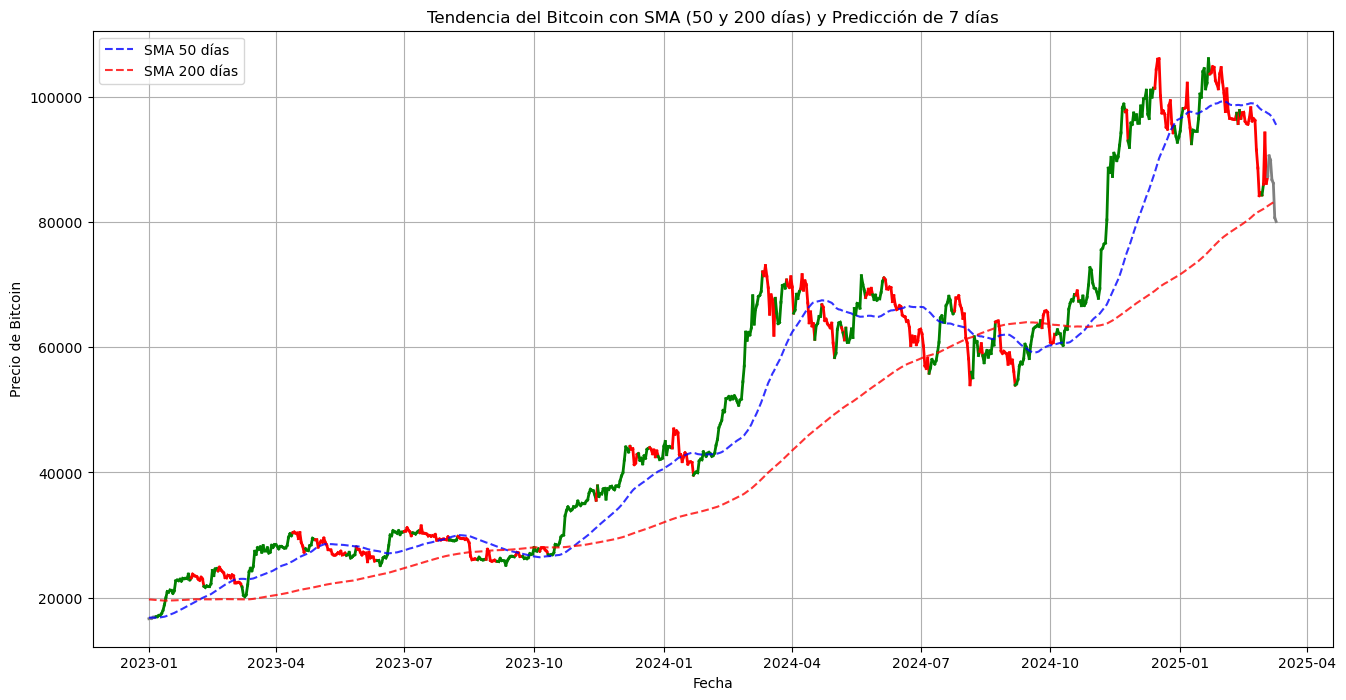

In [3]:
# Crear una visualización donde la línea de "close_binance" cambie de color según la tendencia futura
# Agregando un color adicional para la tendencia neutral

df_plot = df
# Configurar la figura
plt.figure(figsize=(16, 8))

# Recorrer el dataset para cambiar el color del precio de cierre según la tendencia
for i in range(1, len(df_plot)):
    if df_plot.iloc[i]['tendencia_futura_7d'] == 1:
        color = 'green'  # Alcista
    elif df_plot.iloc[i]['tendencia_futura_7d'] == -1:
        color = 'red'  # Bajista
    else:
        color = 'gray'  # Neutral

    plt.plot(df_plot['timestamp'].iloc[i-1:i+1], df_plot['close_binance'].iloc[i-1:i+1], color=color, linewidth=2)

# Graficar las medias móviles
plt.plot(df_plot['timestamp'], df_plot['SMA_50_binance'], label="SMA 50 días", linestyle="dashed", color="blue", alpha=0.8)
plt.plot(df_plot['timestamp'], df_plot['SMA_200_binance'], label="SMA 200 días", linestyle="dashed", color="red", alpha=0.8)

# Configuración de la gráfica
plt.xlabel("Fecha")
plt.ylabel("Precio de Bitcoin")
plt.title("Tendencia del Bitcoin con SMA (50 y 200 días) y Predicción de 7 días")
plt.legend()
plt.grid()

# Mostrar la gráfica mejorada con colores en la línea de precio
plt.show()

# Correlacion con variable respuesta

In [4]:
corr_matrix = df[['open_binance', 'high_binance', 'low_binance', 'close_binance', 'volumen_binance', 'trades_binance',
                 'close_sp500', 'high_sp500', 'low_sp500', 'open_sp500', 'volume_sp500',
                 'close_nasdaq', 'high_nasdaq', 'low_nasdaq', 'open_nasdaq', 'volume_nasdaq',
                 'close_dxy', 'high_dxy', 'low_dxy', 'open_dxy', 'pct_cambio_7d', 'pct_cambio_30d']].dropna().corr(method='pearson')

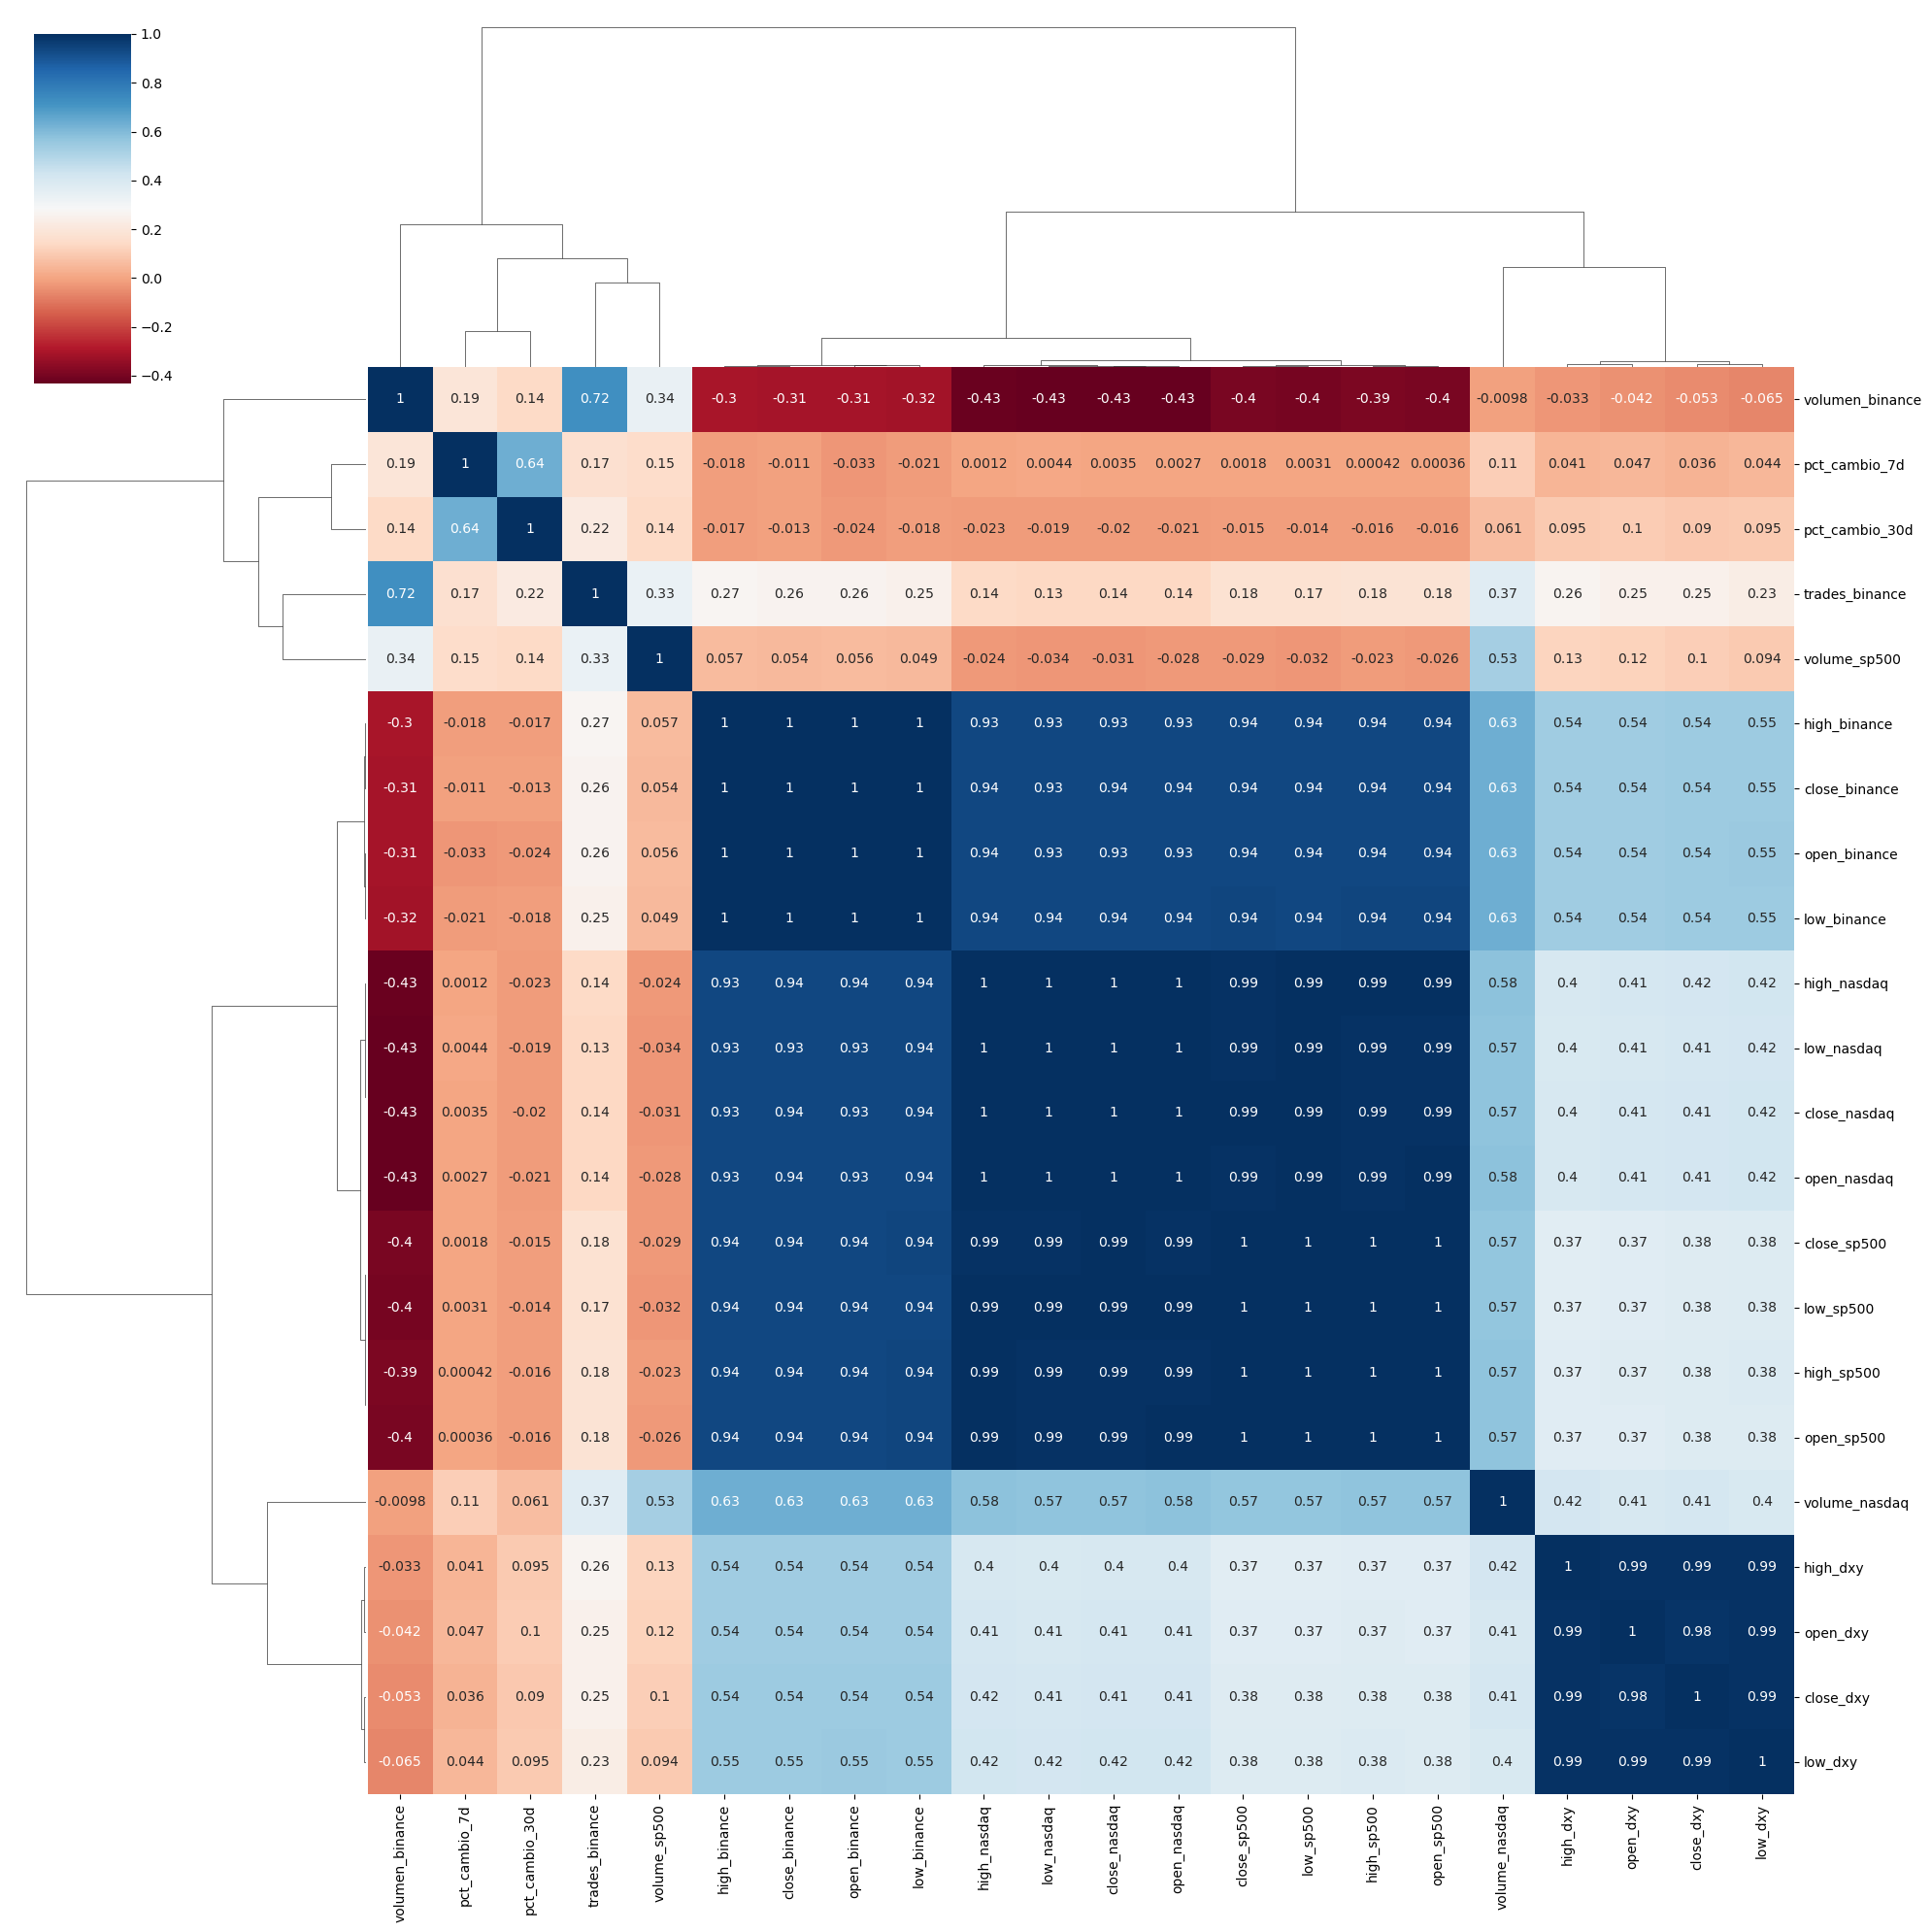

In [5]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(20, 20))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()